# Ngô Minh Khôi - 6451071037
## Môn học: IT1.231.3 - Khai thác dữ liệu
### Bai2

### Câu 1

In [1]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 1: Đọc dữ liệu và thống kê thông tin cơ bản
import pandas as pd
import numpy as np

print("Ngô Minh Khôi - 6451071037")
df = pd.read_csv(r"dataset/titanic.csv")

print("--- 5 Dòng đầu tiên của dữ liệu (df.head()) ---")
print(df.head())

print("\n--- Thông tin cấu trúc dữ liệu (df.info()) ---")
df.info()

print("\n--- Thống kê các thuộc tính định lượng (df.describe()) ---")
print(df.describe())


Ngô Minh Khôi - 6451071037
--- 5 Dòng đầu tiên của dữ liệu (df.head()) ---
   pclass  survived  ...   body                        home.dest
0       1         1  ...    NaN                     St Louis, MO
1       1         1  ...    NaN  Montreal, PQ / Chesterville, ON
2       1         0  ...    NaN  Montreal, PQ / Chesterville, ON
3       1         0  ...  135.0  Montreal, PQ / Chesterville, ON
4       1         0  ...    NaN  Montreal, PQ / Chesterville, ON

[5 rows x 14 columns]

--- Thông tin cấu trúc dữ liệu (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   tic

### Câu 2

In [2]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 2: Liệt kê 5 thuộc tính có số lượng giá trị rỗng nhiều nhất
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_csv(r"dataset/titanic.csv")

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

print("Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:")
print(missing_data.head(5))


Ngô Minh Khôi - 6451071037
Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:
           Total     %
body        1188  90.8
cabin       1014  77.5
boat         823  62.9
home.dest    564  43.1
age          263  20.1


### Câu 3

Ngô Minh Khôi - 6451071037
Nhận xét:
1. Trẻ em nam trong độ tuổi từ 1 đến 10 có tỷ lệ sống sót cao vượt trội.
2. Nữ giới có cơ hội sống sót rất cao trong khoảng độ tuổi từ 12 đến 40 tuổi.
3. Nam giới độ tuổi từ 18 đến 27 có tỷ lệ tử vong cao nhất.
4. Nhìn chung, chính sách ưu tiên phụ nữ và trẻ em thể hiện rõ ràng khi tỷ lệ sống sót của nữ ở hầu hết mọi độ tuổi đều cao hơn nam.


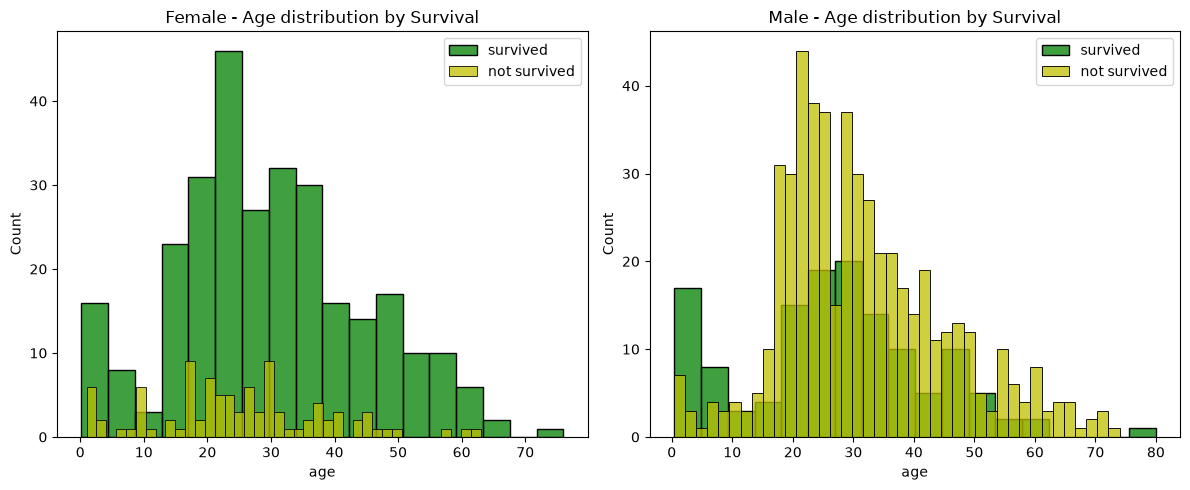

In [3]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 3: Khảo sát mối liên quan giữa Age, Sex và Survived
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Ngô Minh Khôi - 6451071037")
df = pd.read_csv(r"dataset/titanic.csv")

survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female - Age distribution by Survival')

ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
ax.set_title('Male - Age distribution by Survival')

plt.tight_layout()
plt.savefig(r"figures/p1_b2_c3.png", dpi=150)
plt.show()

print("""Nhận xét:
1. Trẻ em nam trong độ tuổi từ 1 đến 10 có tỷ lệ sống sót cao vượt trội.
2. Nữ giới có cơ hội sống sót rất cao trong khoảng độ tuổi từ 12 đến 40 tuổi.
3. Nam giới độ tuổi từ 18 đến 27 có tỷ lệ tử vong cao nhất.
4. Nhìn chung, chính sách ưu tiên phụ nữ và trẻ em thể hiện rõ ràng khi tỷ lệ sống sót của nữ ở hầu hết mọi độ tuổi đều cao hơn nam.""")


### Câu 4

Ngô Minh Khôi - 6451071037
Nhận xét:
1. Cổng lên tàu (Embarked) có mối quan hệ rõ rệt với tỷ lệ sống sót và phụ thuộc theo giới tính:
   - Phụ nữ lên tàu ở cổng Q và cổng S có tỷ lệ sống sót rất cao; ở cổng C tỷ lệ phụ nữ sống sót có phần giảm nhẹ đối với hạng vé 3.
   - Đối với nam giới, những người lên tàu ở cổng C có tỷ lệ sống sót cao hơn so với cổng Q và S.
2. Loại vé (Pclass) tỷ lệ thuận với khả năng sống sót:
   - Hạng vé 1 (Pclass=1) có tỷ lệ sống sót cao nhất (trên 60%).
   - Hạng vé 3 (Pclass=3) có tỷ lệ sống sót thấp nhất (khoảng 25%), cho thấy hành khách mua vé hạng sang được ưu tiên cứu nạn đầu tiên.


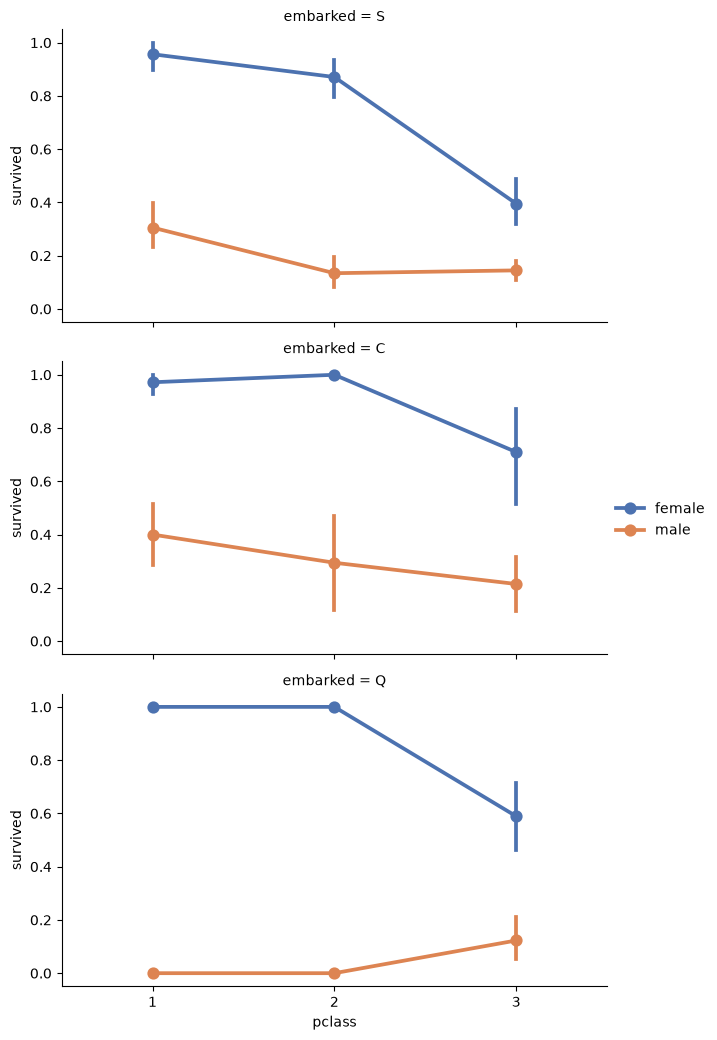

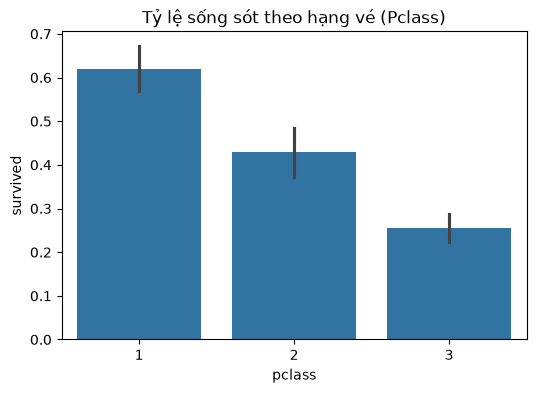

In [4]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 4: Khảo sát Embarked, Pclass với Survived theo Sex
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Ngô Minh Khôi - 6451071037")
df = pd.read_csv(r"dataset/titanic.csv")

FacetGrid = sns.FacetGrid(df, row='embarked', height=3.5, aspect=1.8)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep', order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()
plt.savefig(r"figures/p1_b2_c4_pointplot.png", dpi=150)
plt.show()

plt.figure(figsize=(6, 4))
sns.barplot(x='pclass', y='survived', data=df)
plt.title('Tỷ lệ sống sót theo hạng vé (Pclass)')
plt.savefig(r"figures/p1_b2_c4_barplot.png", dpi=150)
plt.show()

print("""Nhận xét:
1. Cổng lên tàu (Embarked) có mối quan hệ rõ rệt với tỷ lệ sống sót và phụ thuộc theo giới tính:
   - Phụ nữ lên tàu ở cổng Q và cổng S có tỷ lệ sống sót rất cao; ở cổng C tỷ lệ phụ nữ sống sót có phần giảm nhẹ đối với hạng vé 3.
   - Đối với nam giới, những người lên tàu ở cổng C có tỷ lệ sống sót cao hơn so với cổng Q và S.
2. Loại vé (Pclass) tỷ lệ thuận với khả năng sống sót:
   - Hạng vé 1 (Pclass=1) có tỷ lệ sống sót cao nhất (trên 60%).
   - Hạng vé 3 (Pclass=3) có tỷ lệ sống sót thấp nhất (khoảng 25%), cho thấy hành khách mua vé hạng sang được ưu tiên cứu nạn đầu tiên.""")


### Câu 5

Ngô Minh Khôi - 6451071037
Thống kê hành khách đi một mình (1) và đi cùng người thân (0):
not_alone
1    790
0    519
Name: count, dtype: int64
Số người đi một mình: 790 người
Số người đi cùng người thân: 519 người
Nhận xét:
1. Có 790 người đi một mình và 519 người đi cùng người thân.
2. Hành khách đi cùng từ 1 đến 3 người thân có tỷ lệ sống sót cao nhất (đặc biệt là 3 người thân đạt trên 70%).
3. Hành khách đi một mình hoặc đi trong nhóm gia đình quá đông (từ 7 đến 10 người) có tỷ lệ sống sót thấp nhất.


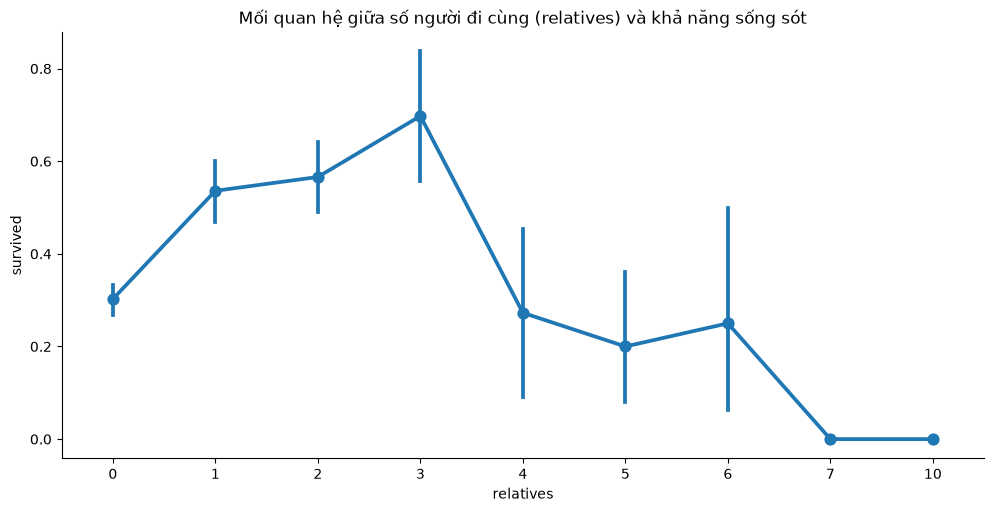

In [5]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 5: Thống kê số người đi cùng và khảo sát với Survived
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Ngô Minh Khôi - 6451071037")
df = pd.read_csv(r"dataset/titanic.csv")

df['relatives'] = df['sibsp'] + df['parch']
df['not_alone'] = 0
df.loc[df['relatives'] == 0, 'not_alone'] = 1

print("Thống kê hành khách đi một mình (1) và đi cùng người thân (0):")
print(df['not_alone'].value_counts())
print(f"Số người đi một mình: {(df['not_alone'] == 1).sum()} người")
print(f"Số người đi cùng người thân: {(df['not_alone'] == 0).sum()} người")

axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.0, kind='point')
plt.title('Mối quan hệ giữa số người đi cùng (relatives) và khả năng sống sót')
plt.savefig(r"figures/p1_b2_c5.png", dpi=150)
plt.show()

print("""Nhận xét:
1. Có 790 người đi một mình và 519 người đi cùng người thân.
2. Hành khách đi cùng từ 1 đến 3 người thân có tỷ lệ sống sót cao nhất (đặc biệt là 3 người thân đạt trên 70%).
3. Hành khách đi một mình hoặc đi trong nhóm gia đình quá đông (từ 7 đến 10 người) có tỷ lệ sống sót thấp nhất.""")


### Câu 6

In [6]:
# Ngô Minh Khôi - 6451071037
# Bài 2 - Câu 6: Tiền xử lý dữ liệu và tạo thuộc tính mới
import pandas as pd
import numpy as np
import re

print("Ngô Minh Khôi - 6451071037")
df = pd.read_csv(r"dataset/titanic.csv")

# 1. Trích xuất đặc trưng deck từ cabin và loại bỏ cabin
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df['cabin'] = df['cabin'].fillna("U0")
df['deck'] = df['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
df['deck'] = df['deck'].map(deck)
df['deck'] = df['deck'].fillna(0).astype(int)
df.drop(columns=['cabin'], inplace=True)

# 2. Xóa các thuộc tính không cần thiết
df.drop(columns=['ticket', 'boat', 'body', 'home.dest'], inplace=True, errors='ignore')

# 3. Điền giá trị thiếu cho thuộc tính tuổi (age) ngẫu nhiên quanh [mean - std, mean + std]
np.random.seed(42)
mean_age = df['age'].mean()
std_age = df['age'].std()
is_null_age = df['age'].isnull().sum()
rand_age = np.random.randint(int(mean_age - std_age), int(mean_age + std_age), size=is_null_age)
age_slice = df['age'].copy()
age_slice[np.isnan(age_slice)] = rand_age
df['age'] = age_slice.astype(int)

# 4. Điền giá trị thiếu cho Cổng lên tàu (embarked) bằng giá trị phổ biến nhất ('S')
df['embarked'] = df['embarked'].fillna('S')

# 5. Điền giá trị thiếu cho giá vé (fare) và ép kiểu int
df['fare'] = df['fare'].fillna(df['fare'].median()).astype(int)

# 6. Trích xuất danh hiệu (title) từ tên (name) và mã hóa thành số, sau đó drop name
titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df['title'] = df['name'].str.extract(' ([A-Za-z]+)\.', expand=False)
df['title'] = df['title'].replace(['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['title'] = df['title'].replace('Mlle', 'Miss')
df['title'] = df['title'].replace('Ms', 'Miss')
df['title'] = df['title'].replace('Mme', 'Mrs')
df['title'] = df['title'].map(titles).fillna(0).astype(int)
df.drop(columns=['name'], inplace=True)

# 7. Chuyển đổi giới tính (sex) và cổng lên tàu (embarked) thành số
df['sex'] = df['sex'].map({'male': 0, 'female': 1}).astype(int)
df['embarked'] = df['embarked'].map({'S': 0, 'C': 1, 'Q': 2}).astype(int)

# 8. Chia nhóm tuổi (age) thành 8 nhóm cân bằng
df.loc[df['age'] <= 11, 'age'] = 0
df.loc[(df['age'] > 11) & (df['age'] <= 18), 'age'] = 1
df.loc[(df['age'] > 18) & (df['age'] <= 22), 'age'] = 2
df.loc[(df['age'] > 22) & (df['age'] <= 27), 'age'] = 3
df.loc[(df['age'] > 27) & (df['age'] <= 33), 'age'] = 4
df.loc[(df['age'] > 33) & (df['age'] <= 40), 'age'] = 5
df.loc[(df['age'] > 40) & (df['age'] <= 66), 'age'] = 6
df.loc[df['age'] > 66, 'age'] = 7

# 9. Chia nhóm giá vé (fare) thành 6 nhóm
df.loc[df['fare'] <= 7.91, 'fare'] = 0
df.loc[(df['fare'] > 7.91) & (df['fare'] <= 14.454), 'fare'] = 1
df.loc[(df['fare'] > 14.454) & (df['fare'] <= 31), 'fare'] = 2
df.loc[(df['fare'] > 31) & (df['fare'] <= 99), 'fare'] = 3
df.loc[(df['fare'] > 99) & (df['fare'] <= 250), 'fare'] = 4
df.loc[df['fare'] > 250, 'fare'] = 5

# 10. Tạo các thuộc tính mới
df['relatives'] = df['sibsp'] + df['parch']
df['not_alone'] = (df['relatives'] == 0).astype(int)
df['age_class'] = df['age'] * df['pclass']
df['fare_per_person'] = (df['fare'] / (df['relatives'] + 1)).astype(int)

print("--- 10 dòng đầu dữ liệu sau tiền xử lý hoàn chỉnh ---")
print(df.head(10))

print("\n--- Thông tin các cột sau khi tiền xử lý ---")
print(df.info())
print("\nTổng số giá trị null còn lại:", df.isnull().sum().sum())


Ngô Minh Khôi - 6451071037
--- 10 dòng đầu dữ liệu sau tiền xử lý hoàn chỉnh ---
   pclass  survived  sex  ...  not_alone  age_class  fare_per_person
0       1         1    1  ...          1          4                4
1       1         1    0  ...          0          0                1
2       1         0    1  ...          0          0                1
3       1         0    0  ...          0          4                1
4       1         0    1  ...          0          3                1
5       1         1    0  ...          1          6                2
6       1         1    1  ...          0          6                1
7       1         0    0  ...          1          5                0
8       1         1    1  ...          0          6                1
9       1         0    0  ...          1          7                3

[10 rows x 14 columns]

--- Thông tin các cột sau khi tiền xử lý ---
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 colu